In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#Data download
!wget -N 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

--2026-10-11 22:29:08--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.02s   

Last-modified header missing -- time-stamps turned off.
2026-10-11 22:29:08 (12.5 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [2]:
#Data Preparation

#Define categorical and numerical columns
categorical = ["industry","location","lead_source","employment_status"]
numerical = ["annual_income","number_of_courses_viewed","interaction_count","lead_score"]

#Check missing vaalues
print(df.isnull().sum())

#Iterate over each column and fill null values with NA (for string) or 0.0 for float.
for col in df.columns:
    typ = df[col].dtype
    if str(typ) == "str":
        df[col] = df[col].fillna("NA")
    elif typ == np.float64:
        df[col] = df[col].fillna(0.0)
        
    #print(col)
    #print(df[col].unique()[:5]) #returns unique value in column (first five)
    #print(df[col].nunique()) #returns numnber of unique values
    #print(df[col].count()) #returns count of non-null values
    #print()

print(df.isnull().sum()) 


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [3]:
#Data Split

from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

#Separate converted column (as target)
y_train = df_train['converted']
y_val = df_val['converted']
y_test = df_test['converted']
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [5]:
#Question 1 - ROC AUC feature importance

VariablesToEvaluate = ["lead_score","number_of_courses_viewed","interaction_count","annual_income"]

for Column in VariablesToEvaluate:
    auc = roc_auc_score(y_train, df_train[Column])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[Column])
    print(f'{Column}: {auc:.3f}')

#Answer: lead_score

lead_score: 0.788
number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608


In [6]:
#Question 2 - Training the model

#One hot enconding to transform categorical columns in numerical
dicts = df[categorical + numerical].to_dict(orient='records') #define dicitionary with columns

from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False) #initialize dictionary

train_dict = df_train[categorical + numerical].to_dict(orient='records') #create training X dictionary
X_train = dv.fit_transform(train_dict) # Create matrix of training with categorical columns transformed

#Do same for validation
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

#Define model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

model.fit(X_train, y_train)  # Fit the model

y_pred = model.predict_proba(X_val)[:, 1] #Perform prediction with val data

auc = roc_auc_score(y_val, y_pred)
#if auc < 0.5:
#    auc = roc_auc_score(y_val, -y_pred)

print(round(auc,3))
#Answer - 0.732

0.732


Threshold: 0.00; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.01; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.02; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.03; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.04; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.05; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.06; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.07; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.08; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.09; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.10; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.11; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.12; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.13; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.14; Precision: 0.586; Recall: 1.000; f1 Score:0.739
Threshold: 0.15; Precisio

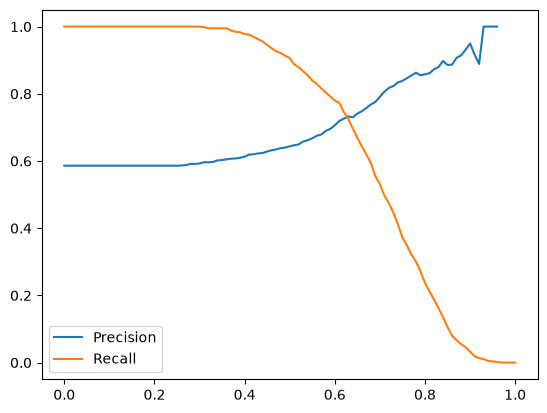

In [7]:
#Question 3- Precision and Recall

from sklearn.metrics import roc_curve
from sklearn.metrics import confusion_matrix

#Calculates precision and recall at all thresholds based on confusion matrix
scores = []
for t in np.linspace(0, 1, 101):
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred >= t).ravel() #Calculate confusion matrix comparing prediction to threshold.
    with np.errstate(divide='ignore', invalid='ignore'):
        p = tp / (tp + fp) #Calculates precision
        r = tp / (tp + fn) #Calculates recall
    f1 = 2*((p*r)/(p+r)) #Calculates F1 Score that considers both precision and recall
    
    scores.append((t, p, r, f1))
    print(f"Threshold: {t:.2f}; Precision: {p:.3f}; Recall: {r:.3f}; f1 Score:{f1:.3f}")
    
columns = ['threshold', 'p', 'r', 'f1']
df_scores = pd.DataFrame(scores, columns=columns)

plt.plot(df_scores.threshold, df_scores['p'], label='Precision')
plt.plot(df_scores.threshold, df_scores['r'], label='Recall')
plt.legend()

#Answer - 0.63

0.758


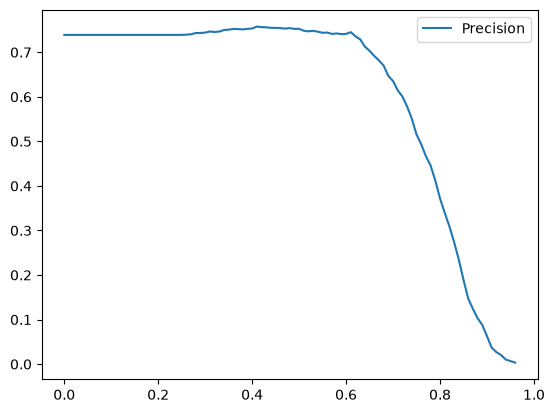

In [8]:
#Question 4 - F1 Score (refer to question 3 code for f1 calculation)
plt.plot(df_scores.threshold, df_scores['f1'], label='Precision')
plt.legend()
print (f"{max(df_scores['f1']):.3f}")
#Answer - t = 0.41

In [9]:
#Create functions to train and test model
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [10]:
#Question 5 - 5-Fold CV

from sklearn.model_selection import KFold
kFoldSplit = KFold(n_splits=5, shuffle=True, random_state=1).split(df_full_train)

scores = []

for train_idx, val_idx in kFoldSplit:
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(f"Score Std: {np.std(scores):.3f}")

#Answer - 0.007

Score Std: 0.007


In [11]:
#Question 6 - Best C

from sklearn.model_selection import KFold
kFold = KFold(n_splits=5, shuffle=True, random_state=1)

CList = [0.000001, 0.001, 1]
for c in CList:
    scores = []
    for train_idx, val_idx in kFold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        dv, model = train(df_train, y_train, C=c)
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print('C=%s %.3f +- %.3f' % (c, np.mean(scores), np.std(scores)))
#Answer - 0.001

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
